# Malinois MPRA 2: only the TFs whose function CAV separates ChIP well

`Malinois MPRA - Allelic Effects vs Function CAV.ipynb` used all 251 TFs. Their CAVs differ a lot in held-out ChIP
AUC (0.47–0.98, mean 0.72): for a TF whose direction barely separates bound from unbound sites, P(bound) is mostly
noise, which may dilute everything. Here the same analyses are repeated on **TFs above an AUC threshold**.

**Thresholds fixed in advance** (no picking afterwards): all TFs, AUC ≥ 0.70, ≥ 0.75, ≥ 0.80. AUC is the held-out
ChIP AUC of the TF's own fit (layer 24); it uses no MPRA data. For each threshold only the motifbreakR calls on those
TFs are kept and every pick is redone, so motifbreakR and the CAV are always compared on the same variants.

**What is computed per threshold, cell (HepG2, K562, SK-N-SH) and variant set (all / active):**

| | as in the first notebook | question |
|---|---|---|
| calibration | 3.3 | Spearman(P, \|Δ\|) of the CAV's pick; and after removing \|alleleDiff\| |
| direction | 3.5 | share of clear effects whose sign motifbreakR gets right: top fifth of P minus bottom fifth |
| within-TF interaction | 3.8 | b(alleleDiff × P) with every TF's own baseline slope |
| prediction | 3.9 T1 vs T0 | out-of-sample Pearson gain of per-TF motifbreakR + P over per-TF motifbreakR (chromosome halves) |
| detection | 3.9 second table | AUROC gain for clear effects, \|alleleDiff\| + P vs \|alleleDiff\| (chromosome halves), 95% CI |
| cell contrast | 3.8 contrast | HepG2 or K562 minus SK-N-SH of the within-TF interaction, 95% CI |

The null for the first four is N2 (P shuffled among the calls of the same TF), run through the whole computation.
CPU only; reads `malinois/` written by the first notebook. About 10–20 minutes.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Load, and the TFs per threshold

In [2]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

MAL = f"{WORK_DIR}/malinois"
POOL = f"{WORK_DIR}/fcav_pool"
OUT = f"{MAL}/eval_nt500m_by_auc"
os.makedirs(OUT, exist_ok=True)
CELLS3 = ["HepG2", "K562", "SKNSH"]
TIERS = [("all TFs", 0.0), ("AUC >= 0.70", 0.70), ("AUC >= 0.75", 0.75), ("AUC >= 0.80", 0.80)]
ACTIVE_MIN, Z_CLEAR = 1.0, 2.0
N_PERM, N_BOOT, SHRINK, LAYER = 500, 300, 20, 24
pd.set_option("display.width", 250)

V = pd.read_csv(f"{MAL}/variants.csv.gz", index_col="vi", dtype={"chrom": str}, low_memory=False)
H = pd.read_csv(f"{MAL}/hits.csv")
CALLS = pd.read_csv(f"{MAL}/calls.csv")
PD_ = f"{MAL}/p_nt500m"
PU = pd.concat([pd.read_csv(f"{PD_}/{f}") for f in os.listdir(PD_) if f.endswith(".csv") and not f.endswith(".part.csv")])
H = H[~H["leak"]].merge(PU, on="uid")
PVM = H.groupby(["vi", "motif"])["P"].max().rename("P").reset_index()
LALL = CALLS.merge(PVM, on=["vi", "motif"])
AUC = {}
for m in LALL["motif"].unique():
    z = np.load(f"{POOL}/fits/nt500m/{m}.npz", allow_pickle=False)
    AUC[m] = float(np.asarray(z["auc"])[[int(l) for l in z["layers"]].index(LAYER)])
LALL["auc"] = LALL["motif"].map(AUC)
rows = []
for name, thr in TIERS:
    d = LALL[LALL["auc"] >= thr]
    rows.append({"threshold": name, "TFs": d["motif"].nunique(), "calls": len(d), "variants": d["vi"].nunique(),
                 "mean AUC of these TFs": np.mean([AUC[m] for m in d["motif"].unique()])})
print(pd.DataFrame(rows).set_index("threshold").to_string(float_format=lambda x: f"{x:.3f}"))

             TFs   calls  variants  mean AUC of these TFs
threshold                                                
all TFs      251  115254     67447                  0.721
AUC >= 0.70  143   68492     48086                  0.797
AUC >= 0.75   95   47116     35708                  0.834
AUC >= 0.80   50   26474     22483                  0.885


## 2. The computations (same definitions as the first notebook)

In [3]:
def rank(x):
    return stats.rankdata(x)


def pear(a, b):
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


def zs(y):
    return (y - y.mean()) / y.std()


def partial_spearman(x, y, z):
    rx, ry, rz = rank(x), rank(y), rank(z)
    res = lambda a: a - np.polyval(np.polyfit(rz, a, 1), rz)
    return pear(res(rx), res(ry))


def recode(g):
    return np.unique(g, return_inverse=True)[1]


def within_tf(v, x, g):
    n = np.bincount(g).astype(float)
    mx, mv = np.bincount(g, x) / n, np.bincount(g, v) / n
    dx, dv = x - mx[g], v - mv[g]
    sxx = np.bincount(g, dx * dx)
    slope = np.divide(np.bincount(g, dx * dv), sxx, out=np.zeros_like(sxx), where=sxx > 1e-12)
    return dv - slope[g] * dx


def fit_within(y, ad, p, g):
    g = recode(g)
    ry = within_tf(y, ad, g)
    X = np.column_stack([within_tf(p, ad, g), within_tf(ad * p, ad, g)])
    b = np.linalg.lstsq(X, ry, rcond=None)[0]
    r = ry - X @ b
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * (r @ r) / (len(y) - 2 * (g.max() + 1) - 2))
    return b[1], se[1]


def tf_pct(p, g):
    o = np.lexsort((p, g))
    gs = g[o]
    st = np.r_[0, np.flatnonzero(gs[1:] != gs[:-1]) + 1]
    cnt = np.diff(np.r_[st, len(gs)])
    q = np.empty(len(p)); q[o] = (np.arange(len(gs)) - np.repeat(st, cnt) + 0.5) / np.repeat(cnt, cnt)
    return q


def tf_slopes(ad, y, g, ng):
    s0 = (ad @ y) / (ad @ ad)
    k = SHRINK * np.mean(ad * ad)
    return (np.bincount(g, ad * y, minlength=ng) + k * s0) / (np.bincount(g, ad * ad, minlength=ng) + k)


def t1_gain(y, ad, p, g, f):
    # out-of-sample Pearson: per-TF motifbreakR + P (T1) minus per-TF motifbreakR (T0)
    g = recode(g); ng = g.max() + 1
    pc = p - (np.bincount(g, p) / np.bincount(g))[g]
    t0, t1 = np.zeros(len(y)), np.zeros(len(y))
    for k in (0, 1):
        tr, te = f != k, f == k
        s = tf_slopes(ad[tr], y[tr], g[tr], ng)
        t0[te] = s[g[te]] * ad[te]
        Z = np.column_stack([ad * pc, pc])
        b = np.linalg.lstsq(Z[tr], y[tr] - s[g[tr]] * ad[tr], rcond=None)[0]
        t1[te] = t0[te] + Z[te] @ b
    return pear(t1, y) - pear(t0, y)


def context(L):
    L = L.sort_values(["vi", "motif"]).reset_index(drop=True)
    VI = np.unique(L["vi"].values)
    cv = np.searchsorted(VI, L["vi"].values)
    cm = pd.factorize(L["motif"])[0]
    X = dict(VI=VI, cv=cv, cm=cm, AD=L["alleleDiff"].values, P0=L["P"].values, base=np.argsort(cm, kind="stable"))
    X["FB"] = pick(np.abs(X["AD"]), cv)
    chrom = V.loc[VI, "chrom"].astype(str).values
    X["FOLD"] = np.array([int(ch) % 2 if ch.isdigit() else 0 for ch in chrom])
    X["Y"] = {c: V.loc[VI, f"d_{c}"].values for c in CELLS3}
    X["SE"] = {c: V.loc[VI, f"se_{c}"].values for c in CELLS3}
    X["SETS"] = {(c, s): np.isfinite(X["Y"][c]) & ((V.loc[VI, f"act_{c}"].values >= ACTIVE_MIN) if s == "active" else True)
                 for c in CELLS3 for s in ("all", "active")}
    return X


def pick(key, cv):
    o = np.lexsort((key, cv))
    return o[np.r_[cv[o][1:] != cv[o][:-1], True]]


def shuffle_tf(X, rng):
    o = np.lexsort((rng.random(len(X["P0"])), X["cm"]))
    out = np.empty_like(X["P0"]); out[X["base"]] = X["P0"][o]
    return out


def all_stats(X, p):
    # per (cell, set): [Spearman(P, |Δ|), same after |alleleDiff|, within-TF b, T1 gain, direction top - bottom fifth]
    FB, AD, cv = X["FB"], X["AD"], X["cv"]
    FC = pick(p + 1e-9 * np.abs(AD), cv)
    PCH, ADCH, PF, ADF, ADMAX, TF = p[FC], AD[FC], p[FB], AD[FB], np.abs(AD[FB]), X["cm"][FB]
    out = {}
    for (c, s), m in X["SETS"].items():
        y = X["Y"][c][m]
        ya = np.abs(y)
        sp = pear(rank(PCH[m]), rank(ya))
        pa = partial_spearman(PCH[m], ya, ADMAX[m])
        bw = fit_within(zs(y), ADF[m], PF[m], TF[m])[0]
        tg = t1_gain(zs(y), ADF[m], PF[m], TF[m], X["FOLD"][m])
        clear = np.abs(y) / X["SE"][c][m] >= Z_CLEAR
        lo, hi = np.quantile(PCH[m], [0.2, 0.8])
        agree = np.sign(ADCH[m]) == np.sign(y)
        top, bot = clear & (PCH[m] >= hi), clear & (PCH[m] <= lo)
        dd = agree[top].mean() - agree[bot].mean() if top.any() and bot.any() else np.nan
        out[c, s] = np.array([sp, pa, bw, tg, dd])
    return out


def detection(X, c, s, rng):
    m = X["SETS"][c, s]
    FB = X["FB"]
    ad, p, g, f = X["AD"][FB][m], X["P0"][FB][m], recode(X["cm"][FB][m]), X["FOLD"][m]
    clear = (np.abs(X["Y"][c][m]) / X["SE"][c][m] >= Z_CLEAR).astype(int)
    q = tf_pct(p, g)
    p0, p1 = np.zeros(len(ad)), np.zeros(len(ad))
    for k in (0, 1):
        tr, te = f != k, f == k
        A0, A1 = np.abs(ad)[:, None], np.column_stack([np.abs(ad), q, np.abs(ad) * q])
        p0[te] = LogisticRegression(max_iter=1000).fit(A0[tr], clear[tr]).decision_function(A0[te])
        p1[te] = LogisticRegression(max_iter=1000).fit(A1[tr], clear[tr]).decision_function(A1[te])
    g0 = roc_auc_score(clear, p1) - roc_auc_score(clear, p0)
    bs = []
    for _ in range(N_BOOT):
        j = rng.integers(0, len(clear), len(clear))
        bs.append(roc_auc_score(clear[j], p1[j]) - roc_auc_score(clear[j], p0[j]))
    return roc_auc_score(clear, p0), g0, np.percentile(bs, 2.5), np.percentile(bs, 97.5)


def contrast(X, c, s, rng):
    FB = X["FB"]
    PF, ADF, TF = X["P0"][FB], X["AD"][FB], X["cm"][FB]
    def one(j, cc):
        mm = j[X["SETS"][cc, s][j]]
        return fit_within(zs(X["Y"][cc][mm]), ADF[mm], PF[mm], TF[mm])[0]
    allv = np.arange(len(X["VI"]))
    u = np.flatnonzero(X["SETS"][c, s] | X["SETS"]["SKNSH", s])
    d = [one(j, c) - one(j, "SKNSH") for j in (rng.choice(u, len(u)) for _ in range(N_BOOT))]
    return one(allv, c) - one(allv, "SKNSH"), np.percentile(d, 2.5), np.percentile(d, 97.5)

## 3. Every threshold

In [4]:
NAMES = ["Spearman(P, |Δ|)", "after removing |alleleDiff|", "within-TF b(alleleDiff x P)", "T1 - T0 Pearson",
         "direction: top - bottom fifth"]
ROWS, CROWS = [], []
t_all = time.time()
for name, thr in TIERS:
    X = context(LALL[LALL["auc"] >= thr])
    rng = np.random.default_rng(7)
    obs = all_stats(X, X["P0"])
    null = [all_stats(X, shuffle_tf(X, rng)) for _ in range(N_PERM)]
    for key, o in obs.items():
        nl = np.array([n_[key] for n_ in null])
        c, s = key
        a0, gain, lo, hi = detection(X, c, s, rng)
        r = {"threshold": name, "cell": c, "variants": s, "n": int(X["SETS"][key].sum()),
             "TFs": len(np.unique(X["cm"][X["FB"]][X["SETS"][key]]))}
        for k, nm in enumerate(NAMES):
            r[nm] = o[k]
            r[f"p N2 {k + 1}"] = np.nanmean(nl[:, k] >= o[k])
        r.update({"AUROC |alleleDiff|": a0, "AUROC gain + P": gain, "AUROC gain CI low": lo, "AUROC gain CI high": hi})
        ROWS.append(r)
    for c in ("HepG2", "K562"):
        for s in ("all", "active"):
            o, lo, hi = contrast(X, c, s, rng)
            CROWS.append({"threshold": name, "contrast": f"{c} - SK-N-SH", "variants": s,
                          "difference in within-TF b": o, "95% CI low": lo, "95% CI high": hi})
    print(f"{name}: {len(np.unique(X['cm']))} TFs, {len(X['VI']):,} variants  [{(time.time() - t_all) / 60:.1f} min]", flush=True)
R = pd.DataFrame(ROWS).set_index(["threshold", "cell", "variants"])
CR = pd.DataFrame(CROWS).set_index(["threshold", "contrast", "variants"])
R.to_csv(f"{OUT}/by_auc.csv"); CR.to_csv(f"{OUT}/by_auc_contrast.csv")
fmt = lambda x: f"{x:+.3f}"
print(f"\np N2 k = share of {N_PERM} TF-wise shuffles of P at least as large as statistic k\n")
print("=== calibration and direction (3.3, 3.5)")
print(R[["n", "TFs", NAMES[0], "p N2 1", NAMES[1], "p N2 2", NAMES[4], "p N2 5"]].to_string(float_format=fmt))
print("\n=== within-TF interaction (3.8) and prediction (3.9)")
print(R[[NAMES[2], "p N2 3", NAMES[3], "p N2 4", "AUROC |alleleDiff|", "AUROC gain + P", "AUROC gain CI low",
         "AUROC gain CI high"]].to_string(float_format=fmt))
print("\n=== cell contrast of the within-TF interaction (bootstrap 95% CI)")
print(CR.to_string(float_format=fmt))

all TFs: 251 TFs, 67,447 variants  [8.0 min]
AUC >= 0.70: 143 TFs, 48,086 variants  [13.9 min]
AUC >= 0.75: 95 TFs, 35,708 variants  [18.0 min]
AUC >= 0.80: 50 TFs, 22,483 variants  [20.9 min]

p N2 k = share of 500 TF-wise shuffles of P at least as large as statistic k

=== calibration and direction (3.3, 3.5)
                                n  TFs  Spearman(P, |Δ|)  p N2 1  after removing |alleleDiff|  p N2 2  direction: top - bottom fifth  p N2 5
threshold   cell  variants                                                                                                                  
all TFs     HepG2 all       67447  245            +0.044  +0.000                       +0.040  +0.000                         +0.119  +0.000
                  active    16607  241            +0.099  +0.000                       +0.086  +0.000                         +0.112  +0.052
            K562  all       67447  245            +0.048  +0.000                       +0.043  +0.000                      

## 4. The same as a picture

One panel per statistic; x = threshold, one line per cell, active variants (filled) and all variants (open).

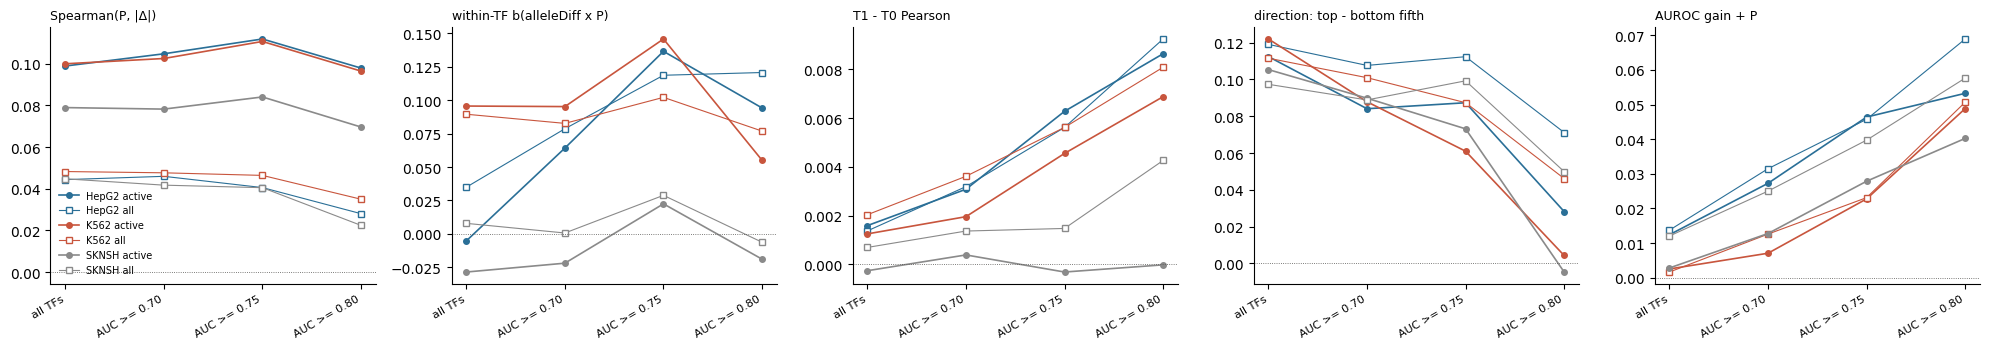

In [5]:
INK = "#52514e"
COL = {"HepG2": "#2a6f97", "K562": "#c8553d", "SKNSH": "#8a8a8a"}
show = [NAMES[0], NAMES[2], NAMES[3], NAMES[4], "AUROC gain + P"]
fig, ax = plt.subplots(1, len(show), figsize=(4 * len(show), 3.6))
xs = np.arange(len(TIERS))
for a, nm in zip(ax, show):
    for c in CELLS3:
        for s, mk in (("active", "o"), ("all", "s")):
            v = [R.loc[(t, c, s), nm] for t, _ in TIERS]
            a.plot(xs, v, "-" + mk, c=COL[c], ms=4, mfc=COL[c] if s == "active" else "white",
                   lw=1.2 if s == "active" else .8, label=f"{c} {s}")
    a.axhline(0, c=INK, lw=.6, ls=":")
    a.set_xticks(xs); a.set_xticklabels([t for t, _ in TIERS], rotation=30, ha="right", fontsize=8)
    a.set_title(nm, fontsize=9, loc="left"); a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/by_auc.png", dpi=150, bbox_inches="tight"); plt.show()

## End

Outputs in `malinois/eval_nt500m_by_auc/`: `by_auc.csv`, `by_auc_contrast.csv`, `by_auc.png`.

In [6]:
from google.colab import runtime
runtime.unassign()